# Block 5 report

**Author:** Kornelius Müller  
**Date:** 25 November 2026



# Block 5: Are my tower years normal or not?

## E1. Question and hypothesis

**Question.** How far is each tower year's mean temperature and precipitation from the WorldClim 1970–2000 normal (BIO1, BIO12)?

**Datasets.** FLUXNET daily meteorology, WorldClim 2.1 (02), and PlantTraits (05). PlantTraits describes the vegetation at each tower; it is context for comparing sites, not a predictor in the climate-anomaly calculation.

**Hypothesis.** I expect the mean temperature in most observed tower-years to be above the WorldClim normal because most observations are from after the 1970–2000 baseline. I do not expect precipitation anomalies to have one consistent direction across all sites and years.

**Scope.** Five towers assigned to student 19. Annual values are descriptive: years within one site are not independent, and five sites are not enough for broad ecological generalization.


## E2. Data

This notebook follows [Part E of the Block 5 assignment](../assignments/block-5-complementary-data.md). Keep the assignment open for the report requirements and hand-in checklist.

Run this notebook from the project root or its `reports/` folder. Install `pandas` and `matplotlib` if needed (`python -m pip install pandas matplotlib`). The Block 5 scripts create the WorldClim and PlantTraits CSVs used below. The Block 4 FLUXNET daily ZIPs are in `scripts/data/raw/` in this project.

The original FLUXNET download date was not recorded in the supplied archive metadata. WorldClim and PlantTraits were extracted on 2026-11-25. The first PlantTraits HTTP request returned 504; rerunning the supplied script succeeded.


In [1]:
from pathlib import Path
import re
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

STUDENT_NO = "19"
MIN_COVERAGE = 0.90  # require 90% of a year's daily observations
ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "tower_sets_block4.csv").exists()),
    Path.cwd(),
)
TOWER_FILE = ROOT / "tower_sets_block4.csv"
RAW_DIR = ROOT / "scripts" / "data" / "raw"
WORLDCLIM_DIR = ROOT / "data" / "external" / "worldclim"
PLANTTRAITS_DIR = ROOT / "data" / "external" / "planttraits"

DOWNLOAD_DATES = {
    "FLUXNET": "date not recorded; ZIPs supplied in scripts/data/raw/",
    "WorldClim 2.1": "2026-11-25",
    "PlantTraits": "2026-11-25",
}

if not TOWER_FILE.exists():
    raise FileNotFoundError(f"{TOWER_FILE} not found. Run the notebook from the project root.")

tower_table = pd.read_csv(TOWER_FILE, dtype={"student_no": str, "site_id": str})
student_key = f"{int(STUDENT_NO):02d}"
sites = tower_table.loc[
    tower_table["student_no"].str.zfill(2).eq(student_key)
].drop_duplicates("site_id").copy()
if sites.empty:
    raise ValueError(f"No tower sites found for student {student_key} in {TOWER_FILE.name}.")

site_ids = sites["site_id"].tolist()
print(f"Student {student_key}: {len(site_ids)} sites — {', '.join(site_ids)}")

PLANTTRAITS_FILE = PLANTTRAITS_DIR / "planttraits_my_sites.csv"
if not PLANTTRAITS_FILE.exists():
    raise FileNotFoundError(f"Required PlantTraits output not found: {PLANTTRAITS_FILE}. Run scripts/block5/05_planttraits.py.")
planttraits = pd.read_csv(PLANTTRAITS_FILE)

Student 19: 5 sites — DE-Hai, RU-Fyo, US-UiD, FR-Gri, CN-Sdq


### PlantTraits at my five towers

PlantTraits is the second selected dataset. These one-cell trait estimates describe differences among tower surroundings; they are not used to calculate the climate anomalies. A 1 km trait pixel is still larger than the typical flux footprint (about 100 m–1 km), and the WorldClim 5′ pixel (~9 km) is much larger. The spatial mismatch means neither sampled cell represents exactly the changing area contributing to every tower measurement. Inspect the `_aoa` area-of-applicability diagnostics below before interpreting the trait values; they are model estimates, not site measurements.


In [2]:
trait_columns = {
    "SLA": "SLA (m² kg⁻¹)",
    "leaf_N_mass": "Leaf N (mg g⁻¹)",
    "stem_density": "Stem density (g cm⁻³)",
    "rooting_depth": "Rooting depth (m)",
}
available_traits = [column for column in trait_columns if column in planttraits.columns]
if not available_traits:
    raise ValueError("No expected PlantTraits columns found; inspect planttraits_my_sites.csv.")

trait_table = (
    sites[["site_id", "site_name", "igbp"]]
    .merge(planttraits[["site_id", *available_traits]], on="site_id", how="left", validate="one_to_one")
    .rename(columns={column: trait_columns[column] for column in available_traits})
)
display(trait_table)

aoa_columns = [f"{column}_aoa" for column in available_traits if f"{column}_aoa" in planttraits.columns]
if aoa_columns:
    print("PlantTraits area-of-applicability diagnostics (inspect before interpreting predictions):")
    display(planttraits[["site_id", *aoa_columns]].loc[planttraits["site_id"].isin(site_ids)])

print("Dataset provenance / download dates:")
provenance = pd.DataFrame(
    [
        ["FLUXNET", "TA_F, P_F, P_F_QC", "tower-specific; daily", DOWNLOAD_DATES["FLUXNET"], "FLUXNET ZIP / FLUXMET_DD; no changes", "Five site citations below; Pastorello et al. (2020)"],
        ["WorldClim 2.1", "BIO1, BIO12", "5′ (~9 km); 1970–2000 normal", DOWNLOAD_DATES["WorldClim 2.1"], "scripts/block5/02_worldclim.py; RES=5m; no changes", "Fick & Hijmans (2017); doi:10.1002/joc.5086"],
        ["PlantTraits", ", ".join(available_traits), "~1 km; static map", DOWNLOAD_DATES["PlantTraits"], "scripts/block5/05_planttraits.py; no changes; first request returned HTTP 504, retry succeeded", "Lusk et al. (2026); doi:10.1038/s41467-026-68996-y; data doi:10.5281/zenodo.14646322"],
    ],
    columns=["Dataset", "Variables", "Resolution / period", "Downloaded on", "Script / processing", "Citation"],
)
display(provenance)

,site_id,site_name,igbp,SLA (m² kg⁻¹),Leaf N (mg g⁻¹),Stem density (g cm⁻³),Rooting depth (m)
0,DE-Hai,Hainich,DBF,24.187972,24.485297,0.433393,0.374899
1,RU-Fyo,Fyodorovskoye,ENF,13.983079,19.817654,0.421109,0.465452
2,US-UiD,University of Illinois Restored Native Prairie,GRA,19.944934,21.525396,0.408856,0.476771
3,FR-Gri,Grignon,CRO,20.473941,24.316870,0.352790,0.431495
4,CN-Sdq,Sidaoqiao,OSH,11.167810,21.978907,0.546123,1.744514


PlantTraits area-of-applicability diagnostics (inspect before interpreting predictions):


,site_id,SLA_aoa,leaf_N_mass_aoa,stem_density_aoa,rooting_depth_aoa
0,DE-Hai,0.0,0.0,0.0,0.0
1,RU-Fyo,0.0,0.0,0.0,0.0
2,US-UiD,0.0,0.0,0.0,0.0
3,FR-Gri,0.0,0.0,0.0,0.0
4,CN-Sdq,0.0,0.0,0.0,0.0


Dataset provenance / download dates:


,Dataset,Variables,Resolution / period,Downloaded on,Script / processing,Citation
0,FLUXNET,"TA_F, P_F, P_F_QC",tower-specific; daily,date not recorded; ZIPs supplied in scripts/da...,FLUXNET ZIP / FLUXMET_DD; no changes,Five site citations below; Pastorello et al. (...
1,WorldClim 2.1,"BIO1, BIO12",5′ (~9 km); 1970–2000 normal,2026-11-25,scripts/block5/02_worldclim.py; RES=5m; no cha...,Fick & Hijmans (2017); doi:10.1002/joc.5086
2,PlantTraits,"SLA, leaf_N_mass, stem_density, rooting_depth",~1 km; static map,2026-11-25,scripts/block5/05_planttraits.py; no changes; ...,Lusk et al. (2026); doi:10.1038/s41467-026-689...


**Table 1.** Nearest-cell PlantTraits estimates for the five towers. Traits are community-weighted map predictions, not direct tower-footprint measurements; all sampled `_aoa` diagnostics are 0 and warrant caution.


### Provenance

| Dataset | Variables used | Resolution and period | Extraction / processing | Citation |
|---|---|---|---|---|
| FLUXNET | `TA_F` (daily mean air temperature, °C); `P_F` (daily precipitation, mm day⁻¹); `P_F_QC` (precipitation quality fraction) | Daily: DE-Hai 2000–2025; RU-Fyo 1998–2025; US-UiD 2008–2024; FR-Gri 2004–2026; CN-Sdq 2013–2024 | `FLUXMET_DD` files in each tower ZIP; annual mean `TA_F`, annual sum `P_F`, and annual mean `P_F_QC` | Site citations and acknowledgements in E6; Pastorello et al. (2020), *Scientific Data* 7, 225, doi:10.1038/s41597-020-0534-3. |
| WorldClim 2.1 | BIO1 (annual mean temperature, °C); BIO12 (annual precipitation, mm) | 5 arc-minutes (~9 km); 1970–2000 normal | Nearest raster cell sampled at each tower coordinate (EPSG:4326) by `scripts/block5/02_worldclim.py` | Fick & Hijmans (2017), *International Journal of Climatology* 37, 4302–4315, doi:10.1002/joc.5086. |
| PlantTraits | SLA (m² kg⁻¹), leaf N (mg g⁻¹), stem density (g cm⁻³), rooting depth (m) | ~1 km trait maps; spatial summary, no time series | Nearest map cell sampled at each tower; values describe the local plant community | Lusk et al. (2026), *Nature Communications* 17, 1203, doi:10.1038/s41467-026-68996-y; data doi:10.5281/zenodo.14646322. |


## E3. Methods

- **Download and extraction:** WorldClim 2.1 was sampled by `scripts/block5/02_worldclim.py` at 5 arc-minutes using the nearest raster cell at each tower's longitude/latitude (EPSG:4326). PlantTraits values were extracted by `scripts/block5/05_planttraits.py`; the script transforms tower coordinates from EPSG:4326 to the map CRS before sampling. The FLUXNET `FLUXMET_DD` CSV was read from each tower's ZIP in `scripts/data/raw/`. WorldClim used the script default `RES = "5m"`; PlantTraits used the seven default trait layers. Neither download script was modified. The first PlantTraits request returned HTTP 504; a later run of the same script succeeded.
- **Processing:** `-9999` is treated as missing. WorldClim BIO1 is already in °C and BIO12 in mm, so no additional scaling is applied. For each site and calendar year, the notebook calculates mean daily `TA_F` and sums daily `P_F`. Temperature years need at least 90% daily coverage. Precipitation totals are not rescaled: a year must contain a valid `P_F` value for every calendar day.
- **Quality and analysis:** the annual mean `P_F_QC` must be at least 0.5 for precipitation to be included, meaning at least half the daily values are marked measured or good-quality gap-filled on average. CN-Sdq and US-UiD are excluded because their precipitation QC is zero throughout. Each annual value is joined to its site's WorldClim BIO1/BIO12 normal, then the notebook calculates temperature and precipitation departures. It reports per-site and overall means, with `n` equal to qualifying tower-years. PlantTraits is summarized per tower as context and is not included in the anomaly calculation.

The FLUXNET `P_F_QC` metadata defines a 0–1 fraction of measured and good-quality gap-filled precipitation. The 0.5 cutoff is an explicit majority-quality rule for this descriptive comparison, not a significance threshold. The original FLUXNET acquisition date is unavailable in the supplied archive metadata.


In [3]:
def require_file(path):
    if not path.exists():
        raise FileNotFoundError(
            f"Required input not found: {path}\n"
            "Run the matching Block 5 download script and place the Block 4 FLUXNET ZIPs in scripts/data/raw/."
        )
    return path


worldclim = pd.read_csv(require_file(WORLDCLIM_DIR / "worldclim_bio_my_sites.csv"))
planttraits = pd.read_csv(require_file(PLANTTRAITS_DIR / "planttraits_my_sites.csv"))

for label, frame in (("WorldClim", worldclim), ("PlantTraits", planttraits)):
    if frame["site_id"].duplicated().any():
        raise ValueError(f"{label} input has more than one row per site_id.")
    missing_sites = sorted(set(site_ids) - set(frame["site_id"]))
    if missing_sites:
        raise ValueError(f"{label} input is missing tower(s): {', '.join(missing_sites)}")

normals = worldclim.loc[worldclim["site_id"].isin(site_ids), ["site_id", "BIO1", "BIO12"]].copy()
normals["BIO1_C"] = pd.to_numeric(normals["BIO1"], errors="coerce")
normals["BIO12_mm"] = pd.to_numeric(normals["BIO12"], errors="coerce")
if normals[["BIO1_C", "BIO12_mm"]].isna().any().any():
    raise ValueError("WorldClim BIO1 or BIO12 is missing for at least one tower.")

# Read the daily FLUXMET_DD file from each tower's Block 4 ZIP.
zip_files = sorted(RAW_DIR.glob("*.zip")) if RAW_DIR.exists() else []
if not zip_files:
    raise FileNotFoundError(f"No FLUXNET ZIP files found in {RAW_DIR}.")

flux_parts = []
found_sites = set()
for zip_path in zip_files:
    match = re.search(r"([A-Z]{2}-[A-Za-z0-9]{3})", zip_path.name)
    if not match or match.group(1) not in site_ids:
        continue
    site_id = match.group(1)
    with zipfile.ZipFile(zip_path) as archive:
        daily_files = sorted(name for name in archive.namelist() if "FLUXMET_DD" in name)
        if not daily_files:
            raise ValueError(f"No FLUXMET_DD file found inside {zip_path.name}.")
        with archive.open(daily_files[0]) as stream:
            frame = pd.read_csv(
                stream,
                usecols=lambda col: col in {"TIMESTAMP", "TA_F", "P_F", "P_F_QC"},
                dtype={"TIMESTAMP": str},
                na_values=[-9999],
            )
    required_columns = {"TIMESTAMP", "TA_F", "P_F", "P_F_QC"}
    if not required_columns.issubset(frame.columns):
        raise ValueError(f"{daily_files[0]} does not contain all required columns: {required_columns}.")
    frame["date"] = pd.to_datetime(frame.pop("TIMESTAMP"), format="%Y%m%d", errors="coerce")
    if frame["date"].isna().any():
        raise ValueError(f"Invalid daily timestamps in {daily_files[0]}.")
    for column in ("TA_F", "P_F", "P_F_QC"):
        frame[column] = pd.to_numeric(frame[column], errors="coerce").replace(-9999, np.nan)
    frame["site_id"] = site_id
    flux_parts.append(frame[["site_id", "date", "TA_F", "P_F", "P_F_QC"]])
    found_sites.add(site_id)

missing_flux = sorted(set(site_ids) - found_sites)
if missing_flux:
    raise FileNotFoundError(f"No daily FLUXMET_DD ZIP found for tower(s): {', '.join(missing_flux)}")

flux = pd.concat(flux_parts, ignore_index=True)
if flux.duplicated(["site_id", "date"]).any():
    raise ValueError("Duplicate site-day rows found in the FLUXNET daily files.")
flux["year"] = flux["date"].dt.year

annual = (
    flux.groupby(["site_id", "year"], as_index=False)
    .agg(
        temp_mean_C=("TA_F", "mean"),
        temp_days=("TA_F", "count"),
        precip_sum_mm=("P_F", "sum"),
        precip_days=("P_F", "count"),
        precip_qc_mean=("P_F_QC", "mean"),
        calendar_days=("date", "nunique"),
    )
)
annual["days_in_year"] = pd.to_datetime(annual["year"].astype(str) + "-01-01").dt.is_leap_year.map(
    {True: 366, False: 365}
)
annual["temp_coverage"] = annual["temp_days"] / annual["days_in_year"]
annual["precip_coverage"] = annual["precip_days"] / annual["days_in_year"]
annual.loc[annual["temp_coverage"] < MIN_COVERAGE, "temp_mean_C"] = np.nan
annual["precip_valid"] = (
    (annual["precip_days"] == annual["days_in_year"])
    & (annual["calendar_days"] == annual["days_in_year"])
    & (annual["precip_qc_mean"] >= 0.5)
)
annual.loc[~annual["precip_valid"], "precip_sum_mm"] = np.nan

results = annual.merge(normals[["site_id", "BIO1_C", "BIO12_mm"]], on="site_id", how="left", validate="many_to_one")
results["temp_anomaly_C"] = results["temp_mean_C"] - results["BIO1_C"]
results["precip_anomaly_mm"] = results["precip_sum_mm"] - results["BIO12_mm"]
results["precip_anomaly_pct"] = 100 * results["precip_anomaly_mm"] / results["BIO12_mm"].where(results["BIO12_mm"] != 0)

print(f"Complete input: {len(site_ids)} towers; {results['year'].nunique()} observed years in the annual table.")
display(results[["site_id", "year", "temp_mean_C", "BIO1_C", "temp_anomaly_C", "precip_sum_mm", "BIO12_mm", "precip_anomaly_mm", "temp_coverage", "precip_coverage", "precip_qc_mean", "precip_valid"]].head(10))

Complete input: 5 towers; 29 observed years in the annual table.


,site_id,year,temp_mean_C,BIO1_C,temp_anomaly_C,precip_sum_mm,BIO12_mm,precip_anomaly_mm,temp_coverage,precip_coverage,precip_qc_mean,precip_valid
0,CN-Sdq,2013,11.120559,8.785501,2.335058,NaN,41.0,NaN,1.0,1.0,0.0,False
1,CN-Sdq,2014,10.640173,8.785501,1.854672,NaN,41.0,NaN,1.0,1.0,0.0,False
2,CN-Sdq,2015,10.886414,8.785501,2.100913,NaN,41.0,NaN,1.0,1.0,0.0,False
3,CN-Sdq,2016,10.804590,8.785501,2.019090,NaN,41.0,NaN,1.0,1.0,0.0,False
4,CN-Sdq,2017,11.481310,8.785501,2.695809,NaN,41.0,NaN,1.0,1.0,0.0,False
5,CN-Sdq,2018,10.208751,8.785501,1.423250,NaN,41.0,NaN,1.0,1.0,0.0,False
6,CN-Sdq,2019,10.919145,8.785501,2.133645,NaN,41.0,NaN,1.0,1.0,0.0,False
7,CN-Sdq,2020,10.775270,8.785501,1.989770,NaN,41.0,NaN,1.0,1.0,0.0,False
8,CN-Sdq,2021,11.270655,8.785501,2.485154,NaN,41.0,NaN,1.0,1.0,0.0,False
9,CN-Sdq,2022,11.232378,8.785501,2.446878,NaN,41.0,NaN,1.0,1.0,0.0,False


## E4. Results

A positive temperature anomaly means that year's FLUXNET annual mean was warmer than the WorldClim normal. Positive precipitation anomaly means that year's precipitation total was wetter. The lines show each tower separately; they are descriptive and do not imply a causal effect. Captions follow each figure and table.


Per-tower mean anomalies (n is the number of qualifying tower-years):


,site_id,temperature_years,mean_temp_anomaly_C,warmer_years,precipitation_years,mean_precip_anomaly_mm,mean_precip_anomaly_pct
0,CN-Sdq,12,2.25,12,0,NaN,NaN
1,DE-Hai,26,1.01,24,24,-70.11,-8.74
2,FR-Gri,22,1.16,20,20,-70.82,-11.03
3,RU-Fyo,28,1.02,25,25,-135.33,-19.64
4,US-UiD,17,0.29,11,0,NaN,NaN


Across 5 towers and 105 qualifying tower-years, the mean temperature anomaly was 1.07 °C.
Across 69 qualifying tower-years, the mean precipitation anomaly was -93.9 mm/year (-13.4% of the WorldClim normal).


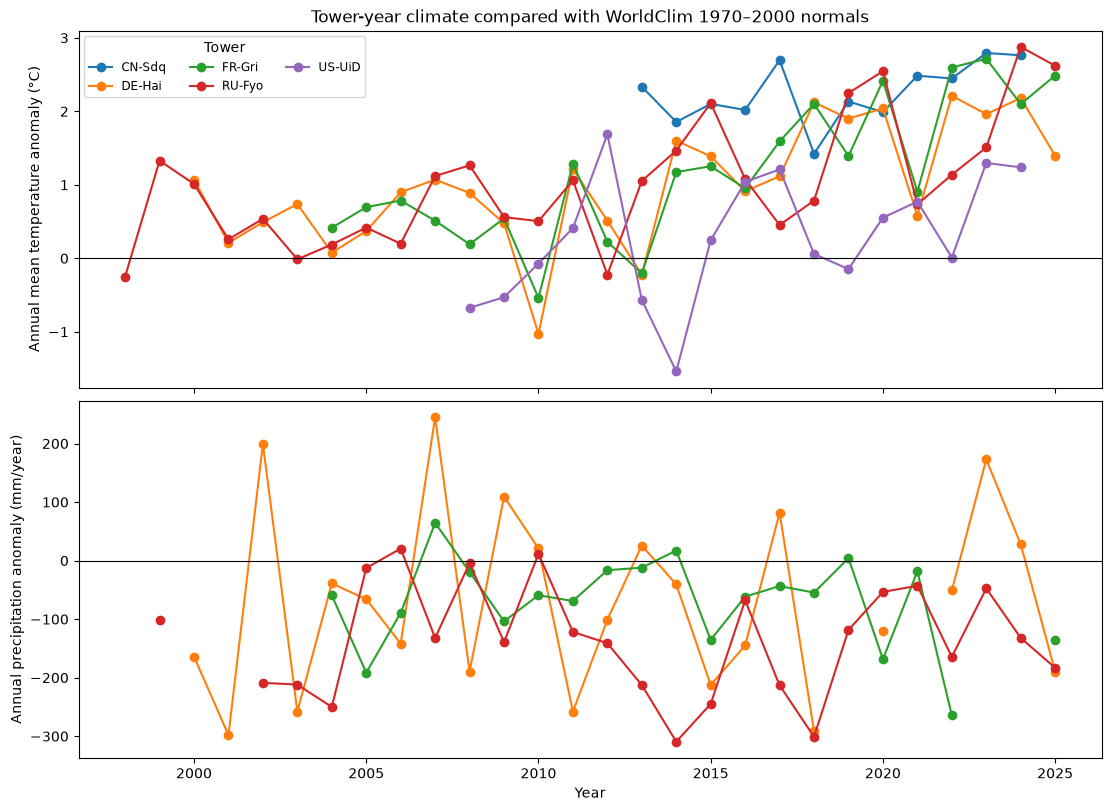

In [4]:
summary = (
    results.groupby("site_id")
    .agg(
        temperature_years=("temp_anomaly_C", "count"),
        mean_temp_anomaly_C=("temp_anomaly_C", "mean"),
        warmer_years=("temp_anomaly_C", lambda values: int((values > 0).sum())),
        precipitation_years=("precip_anomaly_mm", "count"),
        mean_precip_anomaly_mm=("precip_anomaly_mm", "mean"),
        mean_precip_anomaly_pct=("precip_anomaly_pct", "mean"),
    )
    .reset_index()
)
print("Per-tower mean anomalies (n is the number of qualifying tower-years):")
display(summary.round(2))

n_temp = int(results["temp_anomaly_C"].count())
n_precip = int(results["precip_anomaly_mm"].count())
print(
    f"Across {results['site_id'].nunique()} towers and {n_temp} qualifying tower-years, "
    f"the mean temperature anomaly was {results['temp_anomaly_C'].mean():.2f} °C."
)
print(
    f"Across {n_precip} qualifying tower-years, the mean precipitation anomaly was "
    f"{results['precip_anomaly_mm'].mean():.1f} mm/year "
    f"({results['precip_anomaly_pct'].mean():.1f}% of the WorldClim normal)."
)

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, constrained_layout=True)
for site_id, group in results.groupby("site_id"):
    axes[0].plot(group["year"], group["temp_anomaly_C"], marker="o", linewidth=1.5, label=site_id)
    axes[1].plot(group["year"], group["precip_anomaly_mm"], marker="o", linewidth=1.5, label=site_id)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Annual mean temperature anomaly (°C)")
axes[0].set_title("Tower-year climate compared with WorldClim 1970–2000 normals")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Annual precipitation anomaly (mm/year)")
axes[1].set_xlabel("Year")
axes[0].legend(title="Tower", ncol=3, fontsize="small")
plt.show()

**Figure 1.** Annual temperature (°C) and precipitation (mm/year) departures at each tower relative to its WorldClim 1970–2000 normal. Temperature includes years with at least 90% daily coverage. Precipitation is shown only for complete calendar years with mean `P_F_QC` ≥ 0.5; CN-Sdq and US-UiD are omitted because their QC is zero throughout. Lines connect years within the same tower; observations are descriptive, not independent replicates.


## E5. Discussion

The temperature hypothesis is supported descriptively: mean temperature was above the WorldClim normal at all five towers, with a combined mean anomaly of +1.07 °C across 105 tower-years; 92 of those tower-years were warmer than normal. Mean site anomalies ranged from +0.29 °C at US-UiD to +2.25 °C at CN-Sdq, so the response was not identical among sites. For precipitation, I retained only complete calendar years with mean `P_F_QC` of at least 0.5; CN-Sdq and US-UiD were excluded because their precipitation QC is zero throughout. The remaining 69 tower-years averaged 93.9 mm/year below their WorldClim normal, with site means of −70.1 mm at DE-Hai, −70.8 mm at FR-Gri, and −135.3 mm at RU-Fyo; this is descriptive and not independent-site inference. WorldClim's 5′ cells are about 9 km across and PlantTraits' cells about 1 km, while a tower footprint is roughly 100 m–1 km, so each nearest-cell value can include areas outside the flux footprint and miss local heterogeneity. WorldClim is a 1970–2000 climatology rather than a year-specific observation, so each departure combines interannual weather with longer-term climate differences. The analysis uses only five towers, tower-years within a site are temporally dependent, and PlantTraits' area-of-applicability values are 0 for every sampled trait/site, so those trait predictions should not be interpreted as reliable local trait measurements. The complete-year precipitation rule avoids scaling partial totals, but excludes partial years and still cannot resolve biases in the precipitation product; longer records, local precipitation measurements, and footprint-weighted gridded values would improve the comparison.


## E6. Data and citations

**FLUXNET site data citations** (from the Block 4 citation file):

- DE-Hai: Knohl, A., Tiedemann, F., Klosterhalfen, A., Markwitz, C., Fellert, D., Herbst, M., Kolle, O., Kreilein, J., Kutsch, W., and Rebmann, C. (2026). Fluxnet Archive Product from Hainich, 2000–2025. FLUXNET. https://hdl.handle.net/11676/VsQ1NTQTcEO5zRyfZjrBtkQa
- RU-Fyo: Varlagin, A. (2026). Fluxnet Archive Product from Fyodorovskoye, 1998–2025. FLUXNET. https://hdl.handle.net/11676/WDPOlLyjxJ7H43yO9QgAoOfj
- US-UiD: Bernacchi, C., Blakely, B., Moore, C., and Pederson, T. (2026). AmeriFlux FLUXNET-1F US-UiD University of Illinois Restored Native Prairie, Ver. v1.3_r1 (2008–2024). https://doi.org/10.17190/AMF/3027339
- FR-Gri: Buysse, P., Loubet, B., Depuydt, J., Durand, B., Gueudet, J.-C., and Kalalian, J. (2026). Fluxnet Archive Product from Grignon, 2004-01-01–2026-09-06. FLUXNET. https://hdl.handle.net/11676/XSI0ETkKyVVydpJuL7ro3_rQ
- CN-Sdq: Liu, S., Che, T., and Xu, Z. (2026). Fluxnet Archive Product from Sidaoqiao, 2013–2024. FLUXNET. https://hdl.handle.net/11676/3lCvpR-G0sl29NE-OD2rgvf7

Also cite Pastorello, G., Trotta, C., Canfora, E. et al. (2020). The FLUXNET2015 dataset and the ONEFlux processing pipeline for eddy covariance data. *Scientific Data* 7, 225. https://doi.org/10.1038/s41597-020-0534-3.

**Required FLUXNET acknowledgement:** “FLUXNET data products were produced and harmonized by eddy covariance regional networks and data processing centers, including AmeriFlux, ChinaFlux, European Fluxes Database, ICOS, JapanFlux, KoFlux, OzFlux, SAEON, and TERN. These products also include a modified version of ERA5 hourly data provided by the Copernicus Climate Change Service.” Funding for the AmeriFlux data service was provided by the U.S. Department of Energy Office of Science. ChinaFlux data are from the National ecosystem science data center (https://www.nesdc.org.cn).

For ChinaFlux, also cite Yu et al. (2006), https://doi.org/10.1016/j.agrformet.2006.02.011.

- WorldClim: Fick, S.E. & Hijmans, R.J. (2017). WorldClim 2: new 1-km spatial resolution climate surfaces for global land areas. *International Journal of Climatology*, 37, 4302–4315. doi:10.1002/joc.5086.
- PlantTraits: Lusk, D. et al. (2026). *Nature Communications*, 17, 1203. doi:10.1038/s41467-026-68996-y. Data doi:10.5281/zenodo.14646322.

The original FLUXNET download date was not recorded in the supplied archive metadata. WorldClim and PlantTraits were extracted on 2026-11-25. The first PlantTraits HTTP request returned 504; rerunning the supplied script succeeded. No download script changes were made. See the [assignment checklist](../assignments/block-5-complementary-data.md) before hand-in.
